# Convolutional Neural Network (CNN) for Image Classification

This notebook demonstrates a complete, step-by-step implementation of a Convolutional Neural Network (CNN) using **PyTorch** to classify images from the **CIFAR-10** dataset.

## Workflow
* **Setup**: Libraries & Device
* **Data**: Load & Visualize
* **Model**: Define CNN
* **Train**: Train Network
* **Test**: Evaluate Accuracy

In [1]:
# Step 1: Library Imports and Device Setup
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# Configure hardware acceleration if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


In [2]:
# Step 2: Data Loader Definition
def get_data_loaders(batch_size=64):
    # Normalize RGB channels with mean=0.5 and std=0.5
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    # Download CIFAR10 train and test partitions
    train_set = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
    test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

    # Instantiate data loaders for batch processing
    train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True)
    test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size, shuffle=False)

    return train_loader, test_loader

In [3]:
# Step 3: Dataset Visualization Utilities
def imshow(img):
    # Reverse normalization for visualization
    img = img / 2 + 0.5
    np_img = img.numpy()
    # Convert tensor dimensions from (C, H, W) to (H, W, C)
    plt.imshow(np.transpose(np_img, (1, 2, 0)))

def get_sample_images(train_loader):
    data_iter = iter(train_loader)
    images, labels = next(data_iter)
    return images, labels

def visualize(n):
    train_loader, _ = get_data_loaders()
    images, labels = get_sample_images(train_loader)
    plt.figure(figsize=(15, 3))
    for i in range(n):
        plt.subplot(1, n, i + 1)
        imshow(images[i])
        plt.title(f"Label: {labels[i].item()}")
        plt.axis('off')
    plt.show()

In [4]:
# Step 4: CNN Architecture Definition
class CNN(nn.Module):
  def __init__(self):
    super(CNN, self).__init__()

    # Input channels = 3 (RGB), Output filters = 32, kernel_size = 3x3 with padding
    self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
    self.relu = nn.ReLU()
    self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
    self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
    self.dropout = nn.Dropout(0.2)
    self.fc1 = nn.Linear(64 * 8 * 8, 128)
    self.fc2 = nn.Linear(128, 10)

  def forward(self, x):
    """
    Forward pass pipeline:
    Image (3, 32, 32) -> Conv1 -> ReLU -> MaxPool (16, 16) -> Conv2 -> ReLU -> MaxPool (8, 8)
    Flatten -> Fully Connected 1 -> ReLU -> Dropout -> Fully Connected 2 -> Class Logits
    """
    x = self.pool(self.relu(self.conv1(x)))
    x = self.pool(self.relu(self.conv2(x)))
    x = x.view(-1, 64 * 8 * 8)
    x = self.dropout(self.relu(self.fc1(x)))
    x = self.fc2(x)
    return x

In [5]:
# Step 5: Define Loss Function and Optimizer
define_loss_and_optimizer = lambda model: (
    nn.CrossEntropyLoss(),
    optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
)

In [6]:
# Step 6: Model Training Loop
def train(model, train_loader, criterion, optimizer, epochs=5):
    model.train()
    train_losses = []

    for epoch in range(epochs):
        total_loss = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            # Zero the gradients to prevent accumulation
            optimizer.zero_grad()

            # Forward pass & loss calculation
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backpropagation & weight updates
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        train_losses.append(avg_loss)
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.5f}')

    # Plot Training Loss Trend
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, epochs + 1), train_losses, marker="o", linestyle="-", label="Train Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training Loss Curve")
    plt.legend()
    plt.grid(True)
    plt.show()

In [7]:
# Test model function
def test_model(model, test_loader, dataset_type):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f'{dataset_type.capitalize()} Accuracy: {accuracy:.2f}%')

In [8]:
# test_model(model, test_loader, dataset_type = "test") # test accuracy: 62.87 %
# test_model(model, train_loader, dataset_type="training") # training accuracy: 65.51 %

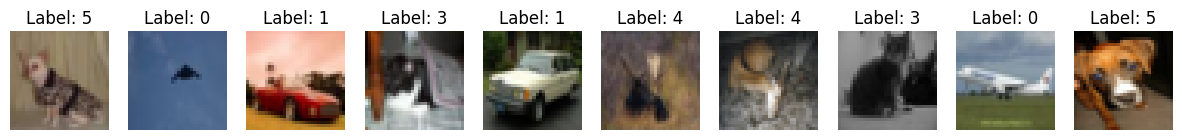

Epoch [1/10], Loss: 2.05944
Epoch [2/10], Loss: 1.71623
Epoch [3/10], Loss: 1.51715
Epoch [4/10], Loss: 1.39401
Epoch [5/10], Loss: 1.31572
Epoch [6/10], Loss: 1.25377
Epoch [7/10], Loss: 1.19819
Epoch [8/10], Loss: 1.15057
Epoch [9/10], Loss: 1.10322
Epoch [10/10], Loss: 1.06469


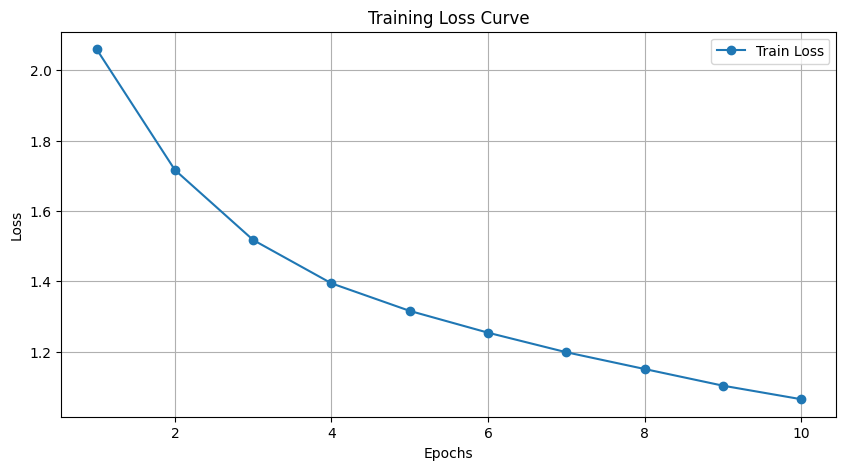

Test Accuracy: 62.87%
Training Accuracy: 65.51%


In [10]:
# main program
if __name__ == "__main__":
  train_loader, test_loader = get_data_loaders()
  visualize(10)
  # training
  model = CNN().to(device)
  criterion, optimizer = define_loss_and_optimizer(model)
  train(model, train_loader, criterion, optimizer, epochs = 10)
  # test
  test_model(model, test_loader, dataset_type = "test")
  test_model(model, train_loader, dataset_type="training")